# Déployez un modèle dans le cloud


# Sommaire :

**1. Préambule**<br />
&emsp;1.1 Problématique<br />
&emsp;1.2 Objectifs dans ce projet<br />
&emsp;1.3 Déroulement des étapes du projet<br />
**2. Choix techniques généraux retenus**<br />
&emsp;2.1 Calcul distribué<br />
&emsp;2.2 Transfert Learning<br />
**3. Déploiement de la solution en local**<br />
&emsp;3.1 Environnement de travail<br />
&emsp;3.2 Installation de Spark<br />
&emsp;3.3 Installation des packages<br />
&emsp;3.4 Import des librairies<br />
&emsp;3.5 Définition des PATH pour charger les images et enregistrer les résultats<br />
&emsp;3.6 Création de la SparkSession<br />
&emsp;3.7 Traitement des données<br />
&emsp;&emsp;3.7.1 Chargement des données<br />
&emsp;&emsp;3.7.2 Préparation du modèle<br />
&emsp;&emsp;3.7.3 Définition du processus de chargement des images et application <br />
&emsp;&emsp;&emsp;&emsp;&emsp;de leur featurisation à travers l'utilisation de pandas UDF<br />
&emsp;&emsp;3.7.4 Exécution des actions d'extractions de features<br />
&emsp;3.8 Chargement des données enregistrées et validation du résultat<br />
**4. Déploiement de la solution sur le cloud**<br />
&emsp;4.1 Choix du prestataire cloud : AWS<br />
&emsp;4.2 Choix de la solution technique : EMR<br />
&emsp;4.3 Choix de la solution de stockage des données : Amazon S3<br />
&emsp;4.4 Configuration de l'environnement de travail<br />
&emsp;4.5 Upload de nos données sur S3<br />
&emsp;4.6 Configuration du serveur EMR<br />
&emsp;&emsp;4.6.1 Étape 1 : Logiciels et étapes<br />
&emsp;&emsp;&emsp;4.6.1.1 Configuration des logiciels<br />
&emsp;&emsp;&emsp;4.6.1.2 Modifier les paramètres du logiciel<br />
&emsp;&emsp;4.6.2 Étape 2 : Matériel<br />
&emsp;&emsp;4.6.3 Étape 3 : Paramètres de cluster généraux<br />
&emsp;&emsp;&emsp;4.6.3.1 Options générales<br />
&emsp;&emsp;&emsp;4.6.3.2 Actions d'amorçage<br />
&emsp;&emsp;4.6.4 Étape 4 : Sécurité<br />
&emsp;&emsp;&emsp;4.6.4.1 Options de sécurité<br />
&emsp;4.7 Instanciation du serveur<br />
&emsp;4.8 Création du tunnel SSH à l'instance EC2 (Maître)<br />
&emsp;&emsp;4.8.1 Création des autorisations sur les connexions entrantes<br />
&emsp;&emsp;4.8.2 Création du tunnel ssh vers le Driver<br />
&emsp;&emsp;4.8.3 Configuration de FoxyProxy<br />
&emsp;&emsp;4.8.4 Accès aux applications du serveur EMR via le tunnel ssh<br />
&emsp;4.9 Connexion au notebook JupyterHub<br />
&emsp;4.10 Exécution du code<br />
&emsp;&emsp;4.10.1 Démarrage de la session Spark<br />
&emsp;&emsp;4.10.2 Installation des packages<br />
&emsp;&emsp;4.10.3 Import des librairies<br />
&emsp;&emsp;4.10.4 Définition des PATH pour charger les images et enregistrer les résultats<br />
&emsp;&emsp;4.10.5 Traitement des données<br />
&emsp;&emsp;&emsp;4.10.5.1 Chargement des données<br />
&emsp;&emsp;&emsp;4.10.5.2 Préparation du modèle<br />
&emsp;&emsp;&emsp;4.10.5.3 Définition du processus de chargement des images<br />
&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;et application de leur featurisation à travers l'utilisation de pandas UDF<br />
&emsp;&emsp;&emsp;4.10.5.4 Exécutions des actions d'extractions de features<br />
&emsp;&emsp;4.10.6 Chargement des données enregistrées et validation du résultat<br />
&emsp;4.11 Suivi de l'avancement des tâches avec le Serveur d'Historique Spark<br />
&emsp;4.12 Résiliation de l'instance EMR<br />
&emsp;4.13 Cloner le serveur EMR (si besoin)<br />
&emsp;4.14 Arborescence du serveur S3 à la fin du projet<br />
**5. Conclusion**

# 1. Préambule

## 1.1 Problématique

La très jeune start-up de l'AgriTech, nommée "**Fruits**!", <br />
cherche à proposer des solutions innovantes pour la récolte des fruits.

La volonté de l’entreprise est de préserver la biodiversité des fruits <br />
en permettant des traitements spécifiques pour chaque espèce de fruits <br />
en développant des robots cueilleurs intelligents.

La start-up souhaite dans un premier temps se faire connaître en mettant <br />
à disposition du grand public une application mobile qui permettrait aux <br />
utilisateurs de prendre en photo un fruit et d'obtenir des informations sur ce fruit.

Pour la start-up, cette application permettrait de sensibiliser le grand public <br /> 
à la biodiversité des fruits et de mettre en place une première version du moteur <br />
de classification des images de fruits.

De plus, le développement de l’application mobile permettra de construire <br />
une première version de l'architecture **Big Data** nécessaire.

## 1.2 Objectifs dans ce projet

1. Développer une première chaîne de traitement des données qui <br />
   comprendra le **preprocessing** et une étape de **réduction de dimension**.
2. Tenir compte du fait que <u>le volume de données va augmenter <br />
   très rapidement</u> après la livraison de ce projet, ce qui implique de:
 - Déployer le traitement des données dans un environnement **Big Data**
 - Développer les scripts en **pyspark** pour effectuer du **calcul distribué**

## 1.3 Déroulement des étapes du projet

Le projet va être réalisé en 2 temps, dans deux environnements différents. <br />
Nous allons dans un premier temps développer et exécuter notre code en local, <br />
en travaillant sur un nombre limité d'images à traiter.

Une fois les choix techniques validés, nous déploierons notre solution <br />
dans un environnement Big Data en mode distribué.

<u>Pour cette raison, ce projet sera divisé en 3 parties</u>:
1. Liste des choix techniques généraux retenus
2. Déploiement de la solution en local
3. Déploiement de la solution dans le cloud

# 2. Choix techniques généraux retenus

## 2.1 Calcul distribué

L’énoncé du projet nous impose de développer des scripts en **pyspark** <br />
afin de <u>prendre en compte l’augmentation très rapide du volume <br />
de donné après la livraison du projet</u>.

Pour comprendre rapidement et simplement ce qu’est **pyspark** <br />
et son principe de fonctionnement, nous vous conseillons de lire <br />
cet article : [PySpark : Tout savoir sur la librairie Python](https://datascientest.com/pyspark)

<u>Le début de l’article nous dit ceci </u>:<br />
« *Lorsque l’on parle de traitement de bases de données sur python, <br />
on pense immédiatement à la librairie pandas. Cependant, lorsqu’on a <br />
affaire à des bases de données trop massives, les calculs deviennent trop lents.<br />
Heureusement, il existe une autre librairie python, assez proche <br />
de pandas, qui permet de traiter des très grandes quantités de données : PySpark.<br />
Apache Spark est un framework open-source développé par l’AMPLab <br />
de UC Berkeley permettant de traiter des bases de données massives <br />
en utilisant le calcul distribué, technique qui consiste à exploiter <br />
plusieurs unités de calcul réparties en clusters au profit d’un seul <br />
projet afin de diviser le temps d’exécution d’une requête.<br />
Spark a été développé en Scala et est au meilleur de ses capacités <br />
dans son langage natif. Cependant, la librairie PySpark propose de <br />
l’utiliser avec le langage Python, en gardant des performances <br />
similaires à des implémentations en Scala.<br />
Pyspark est donc une bonne alternative à la librairie pandas lorsqu’on <br />
cherche à traiter des jeux de données trop volumineux qui entraînent <br />
des calculs trop chronophages.* »

Comme nous le constatons, **pySpark** est un moyen de communiquer <br />
avec **Spark** via le langage **Python**.<br />
**Spark**, quant à lui, est un outil qui permet de gérer et de coordonner <br />
l'exécution de tâches sur des données à travers un groupe d'ordinateurs. <br />
<u>Spark (ou Apache Spark) est un framework open source de calcul distribué <br />
in-memory pour le traitement et l'analyse de données massives</u>.

Un autre [article très intéressant et beaucoup plus complet pour <br />
comprendre le **fonctionnement de Spark**](https://www.veonum.com/apache-spark-pour-les-nuls/), ainsi que le rôle <br />
des **Spark Session** que nous utiliserons dans ce projet.

<u>Voici également un extrait</u>:

*Les applications Spark se composent d’un pilote (« driver process ») <br />
et de plusieurs exécuteurs (« executor processes »). Il peut être configuré <br />
pour être lui-même l’exécuteur (local mode) ou en utiliser autant que <br />
nécessaire pour traiter l’application, Spark prenant en charge la mise <br />
à l’échelle automatique par une configuration d’un nombre minimum <br />
et maximum d’exécuteurs.*

![Schéma de Spark](img/spark-schema.png)

*Le driver (parfois appelé « Spark Session ») distribue et planifie <br />
les tâches entre les différents exécuteurs qui les exécutent et permettent <br />
un traitement réparti. Il est le responsable de l’exécution du code <br />
sur les différentes machines.

Chaque exécuteur est un processus Java Virtual Machine (JVM) distinct <br />
dont il est possible de configurer le nombre de CPU et la quantité de <br />
mémoire qui lui est alloué. <br />
Une seule tâche peut traiter un fractionnement de données à la fois.*

Dans les deux environnements (Local et Cloud) nous utiliserons donc **Spark** <br />
et nous l’exploiterons à travers des scripts python grâce à **PySpark**.

Dans la <u>version locale</u> de notre script nous **simulerons <br />
le calcul distribué** afin de valider que notre solution fonctionne.<br />
Dans la <u>version cloud</u> nous **réaliserons les opérations sur un cluster de machine**.

## 2.2 Transfert Learning

L'énoncé du projet nous demande également de <br />
réaliser une première chaîne de traitement <br />
des données qui comprendra le preprocessing et <br />
une étape de réduction de dimension.

Il est également précisé qu'il n'est pas nécessaire <br />
d'entraîner un modèle pour le moment.

Nous décidons de partir sur une solution de **transfert learning**.

Simplement, le **transfert learning** consiste <br />
à utiliser la connaissance déjà acquise <br />
par un modèle entraîné (ici **MobileNetV2**) pour <br />
l'adapter à notre problématique.

Nous allons fournir au modèle nos images, et nous allons <br />
<u>récupérer l'avant dernière couche</u> du modèle.<br />
En effet la dernière couche de modèle est une couche softmax <br />
qui permet la classification des images ce que nous ne <br />
souhaitons pas dans ce projet.

L'avant dernière couche correspond à un **vecteur <br />
réduit** de dimension (1,1,1280).

Cela permettra de réaliser une première version du moteur <br />
pour la classification des images des fruits.

**MobileNetV2** a été retenu pour sa <u>rapidité d'exécution</u>, <br />
particulièrement adaptée pour le traitement d'un gros volume <br />
de données ainsi que la <u>faible dimensionnalité du vecteur <br />
de caractéristique en sortie</u> (1,1,1280)

# 3. Déploiement de la solution en local


## 3.1 Environnement de travail

Pour des raisons de simplicité, nous développons dans un environnement <br />
Linux Unbuntu (exécuté depuis une machine Windows dans une machine virtuelle)
* Pour installer une machine virtuelle :  https://www.malekal.com/meilleurs-logiciels-de-machine-virtuelle-gratuits-ou-payants/

## 3.2 Installation de Spark

[La première étape consiste à installer Spark ](https://computingforgeeks.com/how-to-install-apache-spark-on-ubuntu-debian/)

## 3.3 Installation des packages

<u>On installe ensuite à l'aide de la commande **pip** <br />
les packages qui nous seront nécessaires</u> :

In [1]:
import boto3

# Initialiser le client S3
s3 = boto3.client('s3')

# Nom du bucket
bucket_name = "fruits-p8-oc"

# Lister les objets dans le bucket
def list_s3_objects(bucket, prefix=""):
    paginator = s3.get_paginator('list_objects_v2')
    pages = paginator.paginate(Bucket=bucket, Prefix=prefix)
    
    for page in pages:
        if 'Contents' in page:
            for obj in page['Contents']:
                print(obj['Key'])  # Affiche chaque chemin complet dans le bucket

# Appel de la fonction pour lister l'arborescence
print("Arborescence du bucket S3 :")
list_s3_objects(bucket_name)


Arborescence du bucket S3 :
Agrech_Laure_1_notebook_112024.ipynb
Results/features_with_pca.csv/_temporary/0/_temporary/attempt_202412170037353172839815383483614_0128_m_000000_372/part-00000-eb6505af-2d37-4ccc-84df-a4d9327a08c1-c000.csv
Results/features_with_pca.parquet/_SUCCESS
Results/features_with_pca.parquet/part-00000-fd603762-e18a-4686-96a2-61b1aad88f28-c000.snappy.parquet
bootstrap-emr.sh
data/Output_cloud/_SUCCESS
data/Output_cloud/part-00000-3a02bad8-b995-43fb-9dca-e27be4c233c2-c000.snappy.parquet
data/Output_cloud/part-00001-3a02bad8-b995-43fb-9dca-e27be4c233c2-c000.snappy.parquet
data/Output_cloud/part-00002-3a02bad8-b995-43fb-9dca-e27be4c233c2-c000.snappy.parquet
data/Output_cloud/part-00003-3a02bad8-b995-43fb-9dca-e27be4c233c2-c000.snappy.parquet
data/Output_cloud/part-00004-3a02bad8-b995-43fb-9dca-e27be4c233c2-c000.snappy.parquet
data/Output_cloud/part-00005-3a02bad8-b995-43fb-9dca-e27be4c233c2-c000.snappy.parquet
data/Output_cloud/part-00006-3a02bad8-b995-43fb-9dca-e27be4

In [2]:
from IPython.core.display import HTML

HTML('''
<style>
    .blue-note {
        background-color: #ADD8E6;
        color: black;
        padding: 10px;
        border-radius: 5px;
        margin-bottom: 10px;
         font-weight: bold;
    }
    .light-blue-note {
        background-color: #ADF8E6;
        color: black;
        padding: 10px;
        border-radius: 5px;
        margin-bottom: 10px;
    }
</style>
''')

<div class="blue-note">
    Voici une annotation avec un fond bleu clair et un texte noir.
</div>


<div class="light-blue-note">
    <b>Executer un jupyter notebook depuis S3 :</b><br>
        -utilisation de PIL
</div>


<div class="light-blue-note"> 
Un cluster est un ensemble de machines (nœuds) qui travaillent ensemble.<br><br>

    
Un nœud est une machine individuelle qui fait partie du cluster.<br><br>
Un cœur est une unité de traitement à l'intérieur de chaque nœud.


Les Instances EC2 sur EMR :
EC2 est le service d'AWS qui permet de créer des machines virtuelles. 

En créant un cluster EMR, ce sont en fait des instances EC2 qui sont utilisées comme nœuds pour le cluster.
On va tester avec 2 configurations différentes (2 EC2, puis 4 EC2) pour exécuter Spark job avec différentes tailles de clusters.

2 Instances EC2 : Le cluster est composé de 2 nœuds de calcul.

4 Instances EC2 : Le cluster est composé de 4 nœuds de calcul.

L'idée est de comparer les performances de l'application en utilisant un nombre différent de nœuds. 

Plus il y a de nœuds, plus les ressources de calcul sont disponibles, ce qui peut accélérer le traitement des données, surtout pour de grands datasets.</div>

## 3.4 Import des librairies

In [3]:
#!pip install tensorflow==2.12.0

In [4]:
#!pip install pandas pyarrow

In [5]:
#!pip install Pandas pillow tensorflow pyspark pyarrow

In [6]:
#!pip uninstall pyarrow -y
#!pip install pyarrow



In [7]:
import sys
print(sys.executable)


/opt/anaconda3/envs/projet8/bin/python


In [8]:
!which python

/opt/anaconda3/envs/projet8/bin/python


In [9]:
import boto3
import pandas as pd
from io import StringIO

In [10]:
import os
from pyspark.sql import SparkSession

In [11]:
import pandas as pd
from PIL import Image
import numpy as np
from io import BytesIO
from IPython.display import display  
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras import Model
from pyspark.sql.functions import col, pandas_udf, PandasUDFType, element_at, split
from pyspark.sql import SparkSession

In [12]:
spark = SparkSession.builder \
    .appName("ReadS3") \
    .config("spark.jars", "/Users/laureagrech/spark/hadoop-aws-3.3.4.jar,/Users/laureagrech/spark/aws-java-sdk-bundle-1.12.563.jar") \
    .config("spark.hadoop.fs.s3a.aws.credentials.provider", "com.amazonaws.auth.DefaultAWSCredentialsProviderChain") \
    .config("spark.hadoop.fs.s3a.endpoint", "s3.amazonaws.com") \
    .getOrCreate()

24/12/17 00:46:15 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 58699)
Traceback (most recent call last):
  File "/opt/anaconda3/envs/projet8/lib/python3.12/socketserver.py", line 318, in _handle_request_noblock
    self.process_request(request, client_address)
  File "/opt/anaconda3/envs/projet8/lib/python3.12/socketserver.py", line 349, in process_request
    self.finish_request(request, client_address)
  File "/opt/anaconda3/envs/projet8/lib/python3.12/socketserver.py", line 362, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "/opt/anaconda3/envs/projet8/lib/python3.12/socketserver.py", line 761, in __init__
    self.handle()
  File "

In [12]:
import os

# Chemin à analyser
base_path = "/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/fruits/fruits-360_dataset/fruits-360/Test"

# Initialisation des compteurs
total_subfolders = 0
total_images = 0
image_extensions = (".jpg", ".jpeg", ".png")  # Extensions d'images à considérer
image_counts = {}  # Dictionnaire pour stocker le nombre d'images par sous-dossier

# Parcours les sous-dossiers et fichiers
for root, dirs, files in os.walk(base_path):
    if root != base_path:  # Ignorer le dossier de base lui-même
        total_subfolders += 1  # Compter les sous-dossiers
        # Compter les fichiers d'image dans le dossier courant
        image_count = sum(1 for file in files if file.endswith(image_extensions))
        total_images += image_count
        image_counts[root] = image_count

# Calcule le minimum et le maximum d'images dans les sous-dossiers
min_images = min(image_counts.values()) if image_counts else 0
max_images = max(image_counts.values()) if image_counts else 0

# Trouve les dossiers correspondants
min_folder = [folder for folder, count in image_counts.items() if count == min_images]
max_folder = [folder for folder, count in image_counts.items() if count == max_images]

print(f"Nombre total de sous-dossiers : {total_subfolders}")
print(f"Nombre total d'images : {total_images}")
print(f"Nombre minimum d'images dans un sous-dossier : {min_images} (Dossier(s) : {', '.join(min_folder)})")
print(f"Nombre maximum d'images dans un sous-dossier : {max_images} (Dossier(s) : {', '.join(max_folder)})")


Nombre total de sous-dossiers : 131
Nombre total d'images : 22688
Nombre minimum d'images dans un sous-dossier : 99 (Dossier(s) : /Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/fruits/fruits-360_dataset/fruits-360/Test/Ginger Root)
Nombre maximum d'images dans un sous-dossier : 328 (Dossier(s) : /Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/fruits/fruits-360_dataset/fruits-360/Test/Grape Blue)


In [13]:
# Chemin à analyser
base_path = "/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/fruits"

# Extensions d'images à considérer
image_extensions = (".jpg", ".jpeg", ".png")

# Initialisation du compteur
total_images = 0

# Parcours les sous-dossiers et fichiers
for root, dirs, files in os.walk(base_path):
    # Compte les fichiers d'image dans le dossier courant
    total_images += sum(1 for file in files if file.endswith(image_extensions))

print(f"Nombre total d'images dans '{base_path}' : {total_images}")

Nombre total d'images dans '/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/fruits' : 102938


In [15]:
import os

# Chemin à analyser
base_path = "/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1"

# Extensions d'images à considérer
image_extensions = (".jpg", ".jpeg", ".png")

# Initialisation du compteur
total_images = 0

# Parcourir les sous-dossiers et fichiers
for root, dirs, files in os.walk(base_path):
    # Compter les fichiers d'image dans le dossier courant
    total_images += sum(1 for file in files if file.endswith(image_extensions))

print(f"Nombre total d'images dans '{base_path}' : {total_images}")


Nombre total d'images dans '/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1' : 110


Catégories détectées : ['Hazelnut', 'Huckleberry', 'Kaki', 'Kiwi', 'Kohlrabi', 'Kumquats', 'Lemon Meyer', 'Lemon', 'Peach Flat', 'Potato White', 'Tomato Heart']


Hazelnut,Huckleberry,Kaki,Kiwi,Kohlrabi,Kumquats,Lemon Meyer,Lemon,Peach Flat,Potato White,Tomato Heart
205_100.jpg,10_100.jpg,11_100.jpg,57_100.jpg,214_100.jpg,0_100.jpg,197_100.jpg,323_100.jpg,41_100.jpg,10_100.jpg,131_100.jpg
211_100.jpg,174_100.jpg,258_100.jpg,62_100.jpg,215_100.jpg,12_100.jpg,199_100.jpg,38_100.jpg,45_100.jpg,125_100.jpg,156_100.jpg
224_100.jpg,251_100.jpg,265_100.jpg,83_100.jpg,227_100.jpg,155_100.jpg,43_100.jpg,41_100.jpg,47_100.jpg,13_100.jpg,35_100.jpg
232_100.jpg,r_205_100.jpg,276_100.jpg,r_327_100.jpg,232_100.jpg,1_100.jpg,54_100.jpg,45_100.jpg,76_100.jpg,165_100.jpg,67_100.jpg
32_100.jpg,r_207_100.jpg,299_100.jpg,r_35_100.jpg,233_100.jpg,251_100.jpg,r_185_100.jpg,r_15_100.jpg,81_100.jpg,16_100.jpg,77_100.jpg
68_100.jpg,r_209_100.jpg,r_161_100.jpg,r_5_100.jpg,243_100.jpg,252_100.jpg,r_189_100.jpg,r_205_100.jpg,93_100.jpg,25_100.jpg,r2_101_100.jpg
r_15_100.jpg,r_216_100.jpg,r_167_100.jpg,r_60_100.jpg,245_100.jpg,286_100.jpg,r_21_100.jpg,r_26_100.jpg,r_37_100.jpg,32_100.jpg,r2_1_100.jpg
r_163_100.jpg,r_44_100.jpg,r_175_100.jpg,r_68_100.jpg,31_100.jpg,304_100.jpg,r_309_100.jpg,r_38_100.jpg,r_45_100.jpg,8_100.jpg,r_110_100.jpg
r_169_100.jpg,r_58_100.jpg,r_202_100.jpg,r_99_100.jpg,r_129_100.jpg,r_195_100.jpg,r_54_100.jpg,r_4_100.jpg,r_78_100.jpg,r2_55_100.jpg,r_132_100.jpg
r_17_100.jpg,r_68_100.jpg,r_77_100.jpg,r_9_100.jpg,r_296_100.jpg,r_275_100.jpg,r_7_100.jpg,r_5_100.jpg,r_91_100.jpg,r_90_100.jpg,r_93_100.jpg

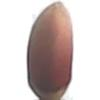
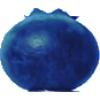
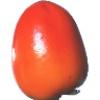
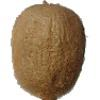
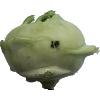
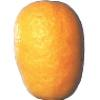
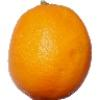
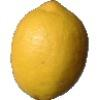
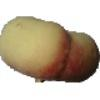
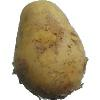
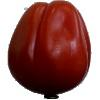
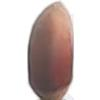
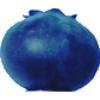
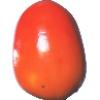
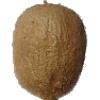
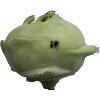
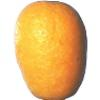
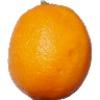
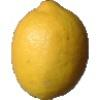
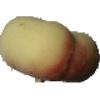
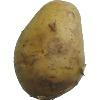
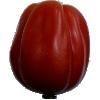
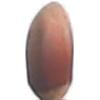
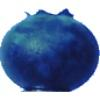
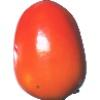
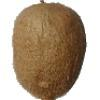
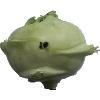
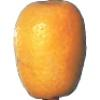
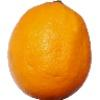
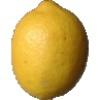
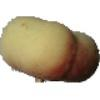
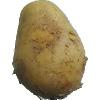
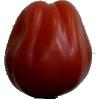
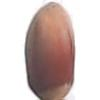
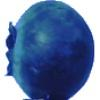
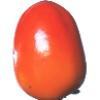
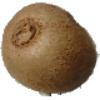
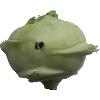
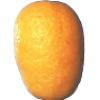
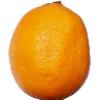
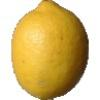
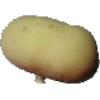
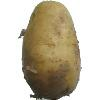
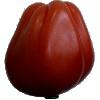
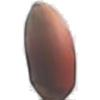
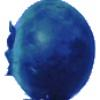
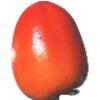
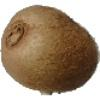
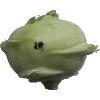
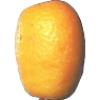
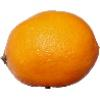
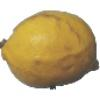
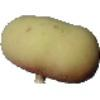
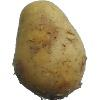
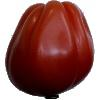
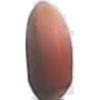
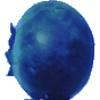
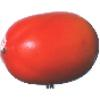
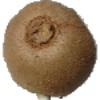
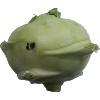
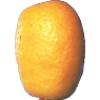
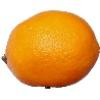
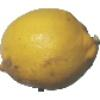
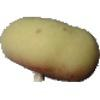
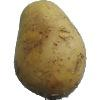
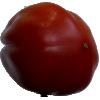
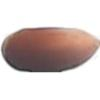
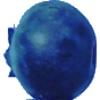
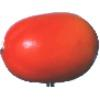
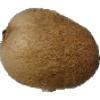
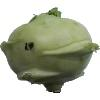
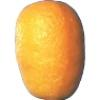
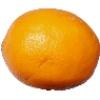
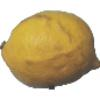
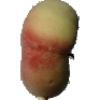
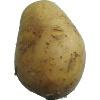
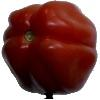
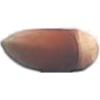
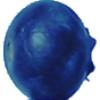
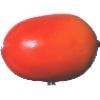
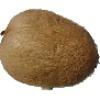
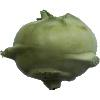
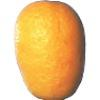
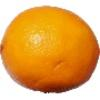
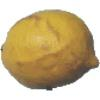
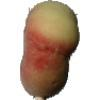
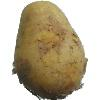
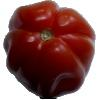
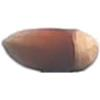
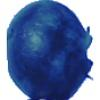
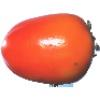
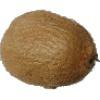
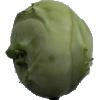
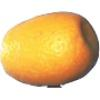
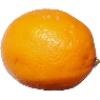
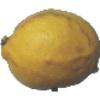
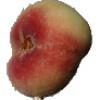
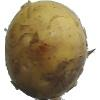
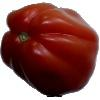
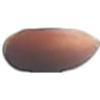
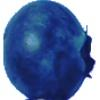
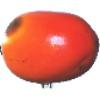
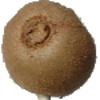
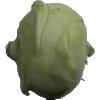
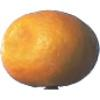
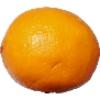
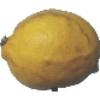
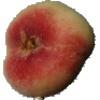
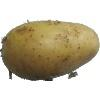
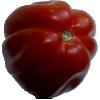


Récapitulatif des images par catégorie :


,Hazelnut,Huckleberry,Kaki,Kiwi,Kohlrabi,Kumquats,Lemon Meyer,Lemon,Peach Flat,Potato White,Tomato Heart
0,data/Test_local/Hazelnut/205_100.jpg,data/Test_local/Huckleberry/10_100.jpg,data/Test_local/Kaki/11_100.jpg,data/Test_local/Kiwi/57_100.jpg,data/Test_local/Kohlrabi/214_100.jpg,data/Test_local/Kumquats/0_100.jpg,data/Test_local/Lemon Meyer/197_100.jpg,data/Test_local/Lemon/323_100.jpg,data/Test_local/Peach Flat/41_100.jpg,data/Test_local/Potato White/10_100.jpg,data/Test_local/Tomato Heart/131_100.jpg
1,data/Test_local/Hazelnut/211_100.jpg,data/Test_local/Huckleberry/174_100.jpg,data/Test_local/Kaki/258_100.jpg,data/Test_local/Kiwi/62_100.jpg,data/Test_local/Kohlrabi/215_100.jpg,data/Test_local/Kumquats/12_100.jpg,data/Test_local/Lemon Meyer/199_100.jpg,data/Test_local/Lemon/38_100.jpg,data/Test_local/Peach Flat/45_100.jpg,data/Test_local/Potato White/125_100.jpg,data/Test_local/Tomato Heart/156_100.jpg
2,data/Test_local/Hazelnut/224_100.jpg,data/Test_local/Huckleberry/251_100.jpg,data/Test_local/Kaki/265_100.jpg,data/Test_local/Kiwi/83_100.jpg,data/Test_local/Kohlrabi/227_100.jpg,data/Test_local/Kumquats/155_100.jpg,data/Test_local/Lemon Meyer/43_100.jpg,data/Test_local/Lemon/41_100.jpg,data/Test_local/Peach Flat/47_100.jpg,data/Test_local/Potato White/13_100.jpg,data/Test_local/Tomato Heart/35_100.jpg
3,data/Test_local/Hazelnut/232_100.jpg,data/Test_local/Huckleberry/r_205_100.jpg,data/Test_local/Kaki/276_100.jpg,data/Test_local/Kiwi/r_327_100.jpg,data/Test_local/Kohlrabi/232_100.jpg,data/Test_local/Kumquats/1_100.jpg,data/Test_local/Lemon Meyer/54_100.jpg,data/Test_local/Lemon/45_100.jpg,data/Test_local/Peach Flat/76_100.jpg,data/Test_local/Potato White/165_100.jpg,data/Test_local/Tomato Heart/67_100.jpg
4,data/Test_local/Hazelnut/32_100.jpg,data/Test_local/Huckleberry/r_207_100.jpg,data/Test_local/Kaki/299_100.jpg,data/Test_local/Kiwi/r_35_100.jpg,data/Test_local/Kohlrabi/233_100.jpg,data/Test_local/Kumquats/251_100.jpg,data/Test_local/Lemon Meyer/r_185_100.jpg,data/Test_local/Lemon/r_15_100.jpg,data/Test_local/Peach Flat/81_100.jpg,data/Test_local/Potato White/16_100.jpg,data/Test_local/Tomato Heart/77_100.jpg
5,data/Test_local/Hazelnut/68_100.jpg,data/Test_local/Huckleberry/r_209_100.jpg,data/Test_local/Kaki/r_161_100.jpg,data/Test_local/Kiwi/r_5_100.jpg,data/Test_local/Kohlrabi/243_100.jpg,data/Test_local/Kumquats/252_100.jpg,data/Test_local/Lemon Meyer/r_189_100.jpg,data/Test_local/Lemon/r_205_100.jpg,data/Test_local/Peach Flat/93_100.jpg,data/Test_local/Potato White/25_100.jpg,data/Test_local/Tomato Heart/r2_101_100.jpg
6,data/Test_local/Hazelnut/r_15_100.jpg,data/Test_local/Huckleberry/r_216_100.jpg,data/Test_local/Kaki/r_167_100.jpg,data/Test_local/Kiwi/r_60_100.jpg,data/Test_local/Kohlrabi/245_100.jpg,data/Test_local/Kumquats/286_100.jpg,data/Test_local/Lemon Meyer/r_21_100.jpg,data/Test_local/Lemon/r_26_100.jpg,data/Test_local/Peach Flat/r_37_100.jpg,data/Test_local/Potato White/32_100.jpg,data/Test_local/Tomato Heart/r2_1_100.jpg
7,data/Test_local/Hazelnut/r_163_100.jpg,data/Test_local/Huckleberry/r_44_100.jpg,data/Test_local/Kaki/r_175_100.jpg,data/Test_local/Kiwi/r_68_100.jpg,data/Test_local/Kohlrabi/31_100.jpg,data/Test_local/Kumquats/304_100.jpg,data/Test_local/Lemon Meyer/r_309_100.jpg,data/Test_local/Lemon/r_38_100.jpg,data/Test_local/Peach Flat/r_45_100.jpg,data/Test_local/Potato White/8_100.jpg,data/Test_local/Tomato Heart/r_110_100.jpg
8,data/Test_local/Hazelnut/r_169_100.jpg,data/Test_local/Huckleberry/r_58_100.jpg,data/Test_local/Kaki/r_202_100.jpg,data/Test_local/Kiwi/r_99_100.jpg,data/Test_local/Kohlrabi/r_129_100.jpg,data/Test_local/Kumquats/r_195_100.jpg,data/Test_local/Lemon Meyer/r_54_100.jpg,data/Test_local/Lemon/r_4_100.jpg,data/Test_local/Peach Flat/r_78_100.jpg,data/Test_local/Potato White/r2_55_100.jpg,data/Test_local/Tomato Heart/r_132_100.jpg
9,data/Test_local/Hazelnut/r_17_100.jpg,data/Test_local/Huckleberry/r_68_100.jpg,data/Test_local/Kaki/r_77_100.jpg,data/Test_local/Kiwi/r_9_100.

In [16]:
import boto3
from PIL import Image
from io import BytesIO
from IPython.display import display, HTML
import pandas as pd
import base64

# Initialise le client S3
s3 = boto3.client('s3')
bucket_name = "fruits-p8-oc"

# Chemin de base des données
base_path = "data/Test_local/"

# Récupère toutes les catégories dynamiquement
try:
    response = s3.list_objects_v2(Bucket=bucket_name, Prefix=base_path, Delimiter='/')
    categories = [prefix['Prefix'].split('/')[-2] for prefix in response.get('CommonPrefixes', [])]
    print(f"Catégories détectées : {categories}")
except Exception as e:
    print(f"Erreur lors de la récupération des catégories : {e}")
    categories = []

# Initialisation des données pour le tableau final
image_data = {category: [] for category in categories}

# Collecte les images pour chaque catégorie
for category in categories:
    prefix = f"{base_path}{category}/"
    try:
        # Liste les objets dans le préfixe de la catégorie
        response = s3.list_objects_v2(Bucket=bucket_name, Prefix=prefix)
        objects = response.get("Contents", [])

        # Collecte les chemins des images
        for obj in objects:
            key = obj["Key"]
            if key.endswith((".jpg", ".jpeg", ".png")):  # Vérifie les formats d'image
                image_data[category].append(key)
    except Exception as e:
        print(f"Erreur pour la catégorie '{category}' : {e}")

# Prépare un tableau pour afficher les images côte à côte
html_table = "<table border='1' style='border-collapse: collapse; text-align: center;'>"
html_table += "<tr>" + "".join(f"<th>{category}</th>" for category in categories) + "</tr>"

max_rows = max(len(image_data[category]) for category in categories)

# Affiche les images côte à côte
for i in range(max_rows):
    html_table += "<tr>"
    for category in categories:
        try:
            key = image_data[category][i] if i < len(image_data[category]) else None
            if key:
                # Télécharge l'image
                response = s3.get_object(Bucket=bucket_name, Key=key)
                image_data_bytes = response['Body'].read()
                image = Image.open(BytesIO(image_data_bytes)).convert('RGB')

                # Converti l'image en Base64
                buffered = BytesIO()
                image.save(buffered, format="JPEG")
                img_str = base64.b64encode(buffered.getvalue()).decode("utf-8")

                # Ajoute l'image encodée dans la cellule HTML
                html_table += f"<td><img src='data:image/jpeg;base64,{img_str}' width='150'><br>{key.split('/')[-1]}</td>"
            else:
                html_table += "<td></td>"
        except Exception as e:
            html_table += f"<td>Erreur : {e}</td>"
    html_table += "</tr>"

html_table += "</table>"

# Affiche le tableau HTML
display(HTML(html_table))

# Crée un DataFrame avec les noms des images par catégorie
data_for_dataframe = {category: image_data[category] for category in categories}

# Remplit les colonnes avec des valeurs vides pour uniformiser la longueur
max_length = max(len(data_for_dataframe[category]) for category in categories)
for category in categories:
    data_for_dataframe[category].extend([""] * (max_length - len(data_for_dataframe[category])))

summary_df = pd.DataFrame(data_for_dataframe)

# Ajoute une ligne avec le total des images
summary_df.loc[max_length] = [f"Total: {len(image_data[category])}" for category in categories]

# Affiche le tableau final
print("\nRécapitulatif des images par catégorie :")
display(summary_df)


### Configurer la SparkSession en Fonction de l’Environnement :

In [17]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, element_at, split, pandas_udf, PandasUDFType, udf
from pyspark.sql.types import ArrayType, FloatType, StringType
from pyspark.ml.feature import PCA
from pyspark.ml.linalg import Vectors, VectorUDT
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import os
import pandas as pd
import time
import logging

In [18]:
np.__version__

'1.26.4'

In [19]:
!which python 

/opt/anaconda3/envs/projet8/bin/python


In [20]:
!jupyter kernelspec list 

Available kernels:
  model2            /Users/laureagrech/Library/Jupyter/kernels/model2
  projet8           /Users/laureagrech/Library/Jupyter/kernels/projet8
  python3           /Users/laureagrech/Library/Jupyter/kernels/python3
  venv_mod          /Users/laureagrech/Library/Jupyter/kernels/venv_mod
  venv_modelling    /Users/laureagrech/Library/Jupyter/kernels/venv_modelling


## 3.5 Définition des PATH pour charger les images <br /> et enregistrer les résultats

Dans cette version locale nous partons du principe que les données <br />
sont stockées dans le même répertoire que le notebook.<br />
Nous n'utilisons qu'un extrait de **110 images** à traiter dans cette <br />
première version en local.<br />
L'extrait des images à charger est stockée dans le dossier **Test_local sur S3**.<br />
Nous enregistrerons le résultat de notre traitement <br />
dans le dossier "**Results**"

In [21]:
# Détection de l'environnement
if "AWS_EXECUTION_ENV" in os.environ:
    ENVIRONMENT = "emr"
else:
    ENVIRONMENT = "local"


# Définit les chemins en fonction de l'environnement
if ENVIRONMENT == "local":
    PATH = os.getcwd() #os.getcwd() récupère le répertoire actuel
    PATH_Data = os.path.join(PATH, 'data/Test1')
    PATH_Result = os.path.join(PATH, 'data/Results')
else:  # EMR ou environnement cloud
    PATH = "s3://fruits-p8-oc/data"
    PATH_Data = os.path.join(PATH, 'Test1')
    PATH_Result = os.path.join(PATH, 'Results')

# Affiche les chemins configurés
print(f"Environnement détecté : {ENVIRONMENT}")
print(f"PATH:        {PATH}\nPATH_Data:   {PATH_Data}\nPATH_Result: {PATH_Result}")

Environnement détecté : local
PATH:        /Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire
PATH_Data:   /Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1
PATH_Result: /Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Results


In [22]:
# Gestion des dépendances -bootstrap sur l'emr

## 3.6 Création de la SparkSession

L’application Spark est contrôlée grâce à un processus de pilotage (driver process) appelé **SparkSession**. <br />
<u>Une instance de **SparkSession** est la façon dont Spark exécute les fonctions définies par l’utilisateur <br />
dans l’ensemble du cluster</u>. <u>Une SparkSession correspond toujours à une application Spark</u>.

<u>Ici nous créons une session spark en spécifiant dans l'ordre</u> :
 1. un **nom pour l'application**, qui sera affichée dans l'interface utilisateur Web Spark "**P8**"
 2. que l'application doit s'exécuter **localement**. <br />
   Nous ne définissons pas le nombre de cœurs à utiliser (comme .master('local[4]) pour 4 cœurs à utiliser), <br />
   nous utiliserons donc tous les cœurs disponibles dans notre processeur.<br />
 3. une option de configuration supplémentaire permettant d'utiliser le **format "parquet"** <br />
   que nous utiliserons pour enregistrer et charger le résultat de notre travail.
 4. vouloir **obtenir une session spark** existante ou si aucune n'existe, en créer une nouvelle

<u>Nous créons également la variable "**sc**" qui est un **SparkContext** issue de la variable **spark**</u> :

In [23]:
# Configuration Spark
if ENVIRONMENT == "local":
    os.environ["PYSPARK_DRIVER_PYTHON"] = "/opt/anaconda3/envs/projet8/bin/python"
    os.environ["PYSPARK_PYTHON"] = "/opt/anaconda3/envs/projet8/bin/python"

    spark = SparkSession.builder \
        .appName("P8") \
        .master("local[*]") \
        .config("spark.jars", 
                "/Users/laureagrech/spark/hadoop-aws-3.3.4.jar,"
                "/Users/laureagrech/spark/aws-java-sdk-bundle-1.12.563.jar") \
        .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
        .config("spark.hadoop.fs.s3a.aws.credentials.provider", 
                "com.amazonaws.auth.DefaultAWSCredentialsProviderChain") \
        .config("spark.hadoop.fs.s3a.endpoint", "s3.amazonaws.com") \
        .getOrCreate()

    spark.sparkContext.setLogLevel("ERROR")

elif ENVIRONMENT == "emr":
    spark = SparkSession.builder \
        .appName("P8") \
        .config("spark.hadoop.fs.s3a.aws.credentials.provider",
                "com.amazonaws.auth.DefaultAWSCredentialsProviderChain") \
        .config("spark.hadoop.fs.s3a.endpoint", "s3.amazonaws.com") \
        .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
        .config("spark.hadoop.fs.s3a.connection.maximum", "500") \
        .config("spark.hadoop.fs.s3a.fast.upload", "true") \
        .config("spark.hadoop.fs.s3a.fast.upload.buffer", "bytebuffer") \
        .config("spark.hadoop.mapreduce.fileoutputcommitter.algorithm.version", "2") \
        .config("spark.speculation", "true") \
        .config("spark.sql.parquet.filterPushdown", "true") \
        .config("spark.sql.hive.convertMetastoreParquet", "true") \
        .getOrCreate()

    spark.sparkContext.setLogLevel("ERROR")

print("SparkSession créée avec succès !")

24/12/17 01:29:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


SparkSession créée avec succès !


In [24]:
sc = spark.sparkContext

<u>Affichage des informations de Spark en cours d'execution</u> :

In [25]:
spark

## 3.7 Traitement des données

<u>Dans la suite de notre flux de travail, <br />
nous allons successivement</u> :
1. Préparer nos données
    1. Importer les images dans un dataframe **pandas UDF**
    2. Associer aux images leur **label**
    3. Préprocesser en **redimensionnant nos images pour <br />
       qu'elles soient compatibles avec notre modèle**
2. Préparer notre modèle
    1. Importer le modèle **MobileNetV2**
    2. Créer un **nouveau modèle** dépourvu de la dernière couche de MobileNetV2
3. Définir le processus de chargement des images et l'application <br />
   de leur featurisation à travers l'utilisation de pandas UDF
3. Exécuter les actions d'extraction de features
4. Enregistrer le résultat de nos actions
5. Tester le bon fonctionnement en chargeant les données enregistrées




### 3.7.1 Chargement des données

Les images sont chargées au format binaire, ce qui offre, <br />
plus de souplesse dans la façon de prétraiter les images.

Avant de charger les images, nous spécifions que nous voulons charger <br />
uniquement les fichiers dont l'extension est **jpg**.

Nous indiquons également de charger tous les objets possibles contenus <br />
dans les sous-dossiers du dossier communiqué.

In [26]:
images = spark.read.format("binaryFile") \
  .option("pathGlobFilter", "*.jpg") \
  .option("recursiveFileLookup", "true") \
  .load(PATH_Data)

<u>Affichage des 5 premières images contenant</u> :
 - le path de l'image
 - la date et heure de sa dernière modification
 - sa longueur
 - son contenu encodé en valeur hexadécimal

<u>Je ne conserve que le **path** de l'image et j'ajoute <br />
    une colonne contenant les **labels** de chaque image</u> :

In [27]:
images = images.withColumn('label', element_at(split(images['path'], '/'),-2))
print(images.printSchema())
print(images.select('path','label').show(5,False))

root
 |-- path: string (nullable = true)
 |-- modificationTime: timestamp (nullable = true)
 |-- length: long (nullable = true)
 |-- content: binary (nullable = true)
 |-- label: string (nullable = true)

None


+----------------------------------------------------------------------------------------------------------+------------+
|path                                                                                                      |label       |
+----------------------------------------------------------------------------------------------------------+------------+
|file:/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1/Kiwi/r_60_100.jpg         |Kiwi        |
|file:/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1/Tomato Heart/r_132_100.jpg|Tomato Heart|
|file:/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1/Kiwi/r_35_100.jpg         |Kiwi        |
|file:/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1/Tomato Heart/r_110_100.jpg|Tomato Heart|
|file:/Users/laureagrech/Desktop/oc/Projets OC/P8/P8_Mode_opÇratoire/data/Test1/Kiwi/r_68_100.jpg         |Kiwi        |
+-----------------------

# Préprocesser en redimensionnant nos images pour
qu'elles soient compatibles avec notre modèle

### 3.7.2 Préparation du modèle

Je vais utiliser la technique du **transfert learning** pour extraire les features des images.<br />
J'ai choisi d'utiliser le modèle **MobileNetV2** pour sa rapidité d'exécution comparée <br />
à d'autres modèles comme *VGG16* par exemple.

Pour en savoir plus sur la conception et le fonctionnement de MobileNetV2, <br />
je vous invite à lire [cet article](https://towardsdatascience.com/review-mobilenetv2-light-weight-model-image-classification-8febb490e61c).

<u>Voici le schéma de son architecture globale</u> : 

![Architecture de MobileNetV2](img/mobilenetv2_architecture.png)

Il existe une dernière couche qui sert à classer les images <br />
selon 1000 catégories que nous ne voulons pas utiliser.<br />
L'idée dans ce projet est de récupérer le **vecteur de caractéristiques <br />
de dimensions (1,1,1280)** qui servira, plus tard, au travers d'un moteur <br />
de classification à reconnaitre les différents fruits du jeu de données.

Comme d'autres modèles similaires, **MobileNetV2**, lorsqu'on l'utilise <br />
en incluant toutes ses couches, attend obligatoirement des images <br />
de dimension (224,224,3). Nos images étant toutes de dimension (100,100,3), <br />
nous devrons simplement les **redimensionner** avant de les confier au modèle.

<u>Dans l'odre</u> :
 1. Nous chargeons le modèle **MobileNetV2** avec les poids **précalculés** <br />
    issus d'**imagenet** et en spécifiant le format de nos images en entrée
 2. Nous créons un nouveau modèle avec:
  - <u>en entrée</u> : l'entrée du modèle MobileNetV2
  - <u>en sortie</u> : l'avant dernière couche du modèle MobileNetV2

In [28]:
from pyspark.sql.functions import lit
test_df = spark.createDataFrame([("test",)], ["value"])
test_df.withColumn("numpy_test", lit(np.__version__)).show()

+-----+----------+
|value|numpy_test|
+-----+----------+
| test|    1.26.4|
+-----+----------+



In [29]:
def list_images(directory, max_images=20):
    """
    Compte le nombre total d'images et affiche un nombre limité de chemins d'images.
    
    :param directory: Le chemin du répertoire à parcourir.
    :param max_images: Le nombre maximal d'images à afficher.
    """
    supported_formats = ('.jpg', '.jpeg', '.png', '.bmp', '.gif', '.tiff')
    image_paths = []  # Liste pour stocker les chemins des images
    
    # Parcourir le répertoire et collecter les chemins des images
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.lower().endswith(supported_formats):
                image_paths.append(os.path.join(root, file))
    
    # Afficher le nombre total d'images trouvées
    total_images = len(image_paths)
    print(f"Nombre total d'images : {total_images}")
    
    # Afficher les max_images premières images
    print(f"Affichage des {min(max_images, total_images)} premières images :")
    for i, path in enumerate(image_paths[:max_images]):
        print(f"{i+1}. {path}")

# Appeler la fonction pour afficher le nombre total et 20 images
list_images("data/Test1", max_images=20)


Nombre total d'images : 110
Affichage des 20 premières images :
1. data/Test1/Huckleberry/r_68_100.jpg
2. data/Test1/Huckleberry/r_209_100.jpg
3. data/Test1/Huckleberry/10_100.jpg
4. data/Test1/Huckleberry/174_100.jpg
5. data/Test1/Huckleberry/r_44_100.jpg
6. data/Test1/Huckleberry/r_207_100.jpg
7. data/Test1/Huckleberry/251_100.jpg
8. data/Test1/Huckleberry/r_216_100.jpg
9. data/Test1/Huckleberry/r_58_100.jpg
10. data/Test1/Huckleberry/r_205_100.jpg
11. data/Test1/Kohlrabi/r_296_100.jpg
12. data/Test1/Kohlrabi/227_100.jpg
13. data/Test1/Kohlrabi/245_100.jpg
14. data/Test1/Kohlrabi/r_129_100.jpg
15. data/Test1/Kohlrabi/214_100.jpg
16. data/Test1/Kohlrabi/232_100.jpg
17. data/Test1/Kohlrabi/31_100.jpg
18. data/Test1/Kohlrabi/233_100.jpg
19. data/Test1/Kohlrabi/215_100.jpg
20. data/Test1/Kohlrabi/243_100.jpg


Affichage du résumé de notre nouveau modèle où nous constatons
que nous récupérons bien en sortie un vecteur de dimension (1, 1, 1280) 

code complet et consolidé pour réutiliser le modèle MobileNetV2 et effectuer l'extraction de caractéristiques (features) en exploitant les fonctionnalités des UDF pandas et de PySpark :

In [30]:
import boto3

# Initialisation du client S3
s3 = boto3.client('s3')
bucket_name = "fruits-p8-oc"

def display_tree(prefix="", indent="", max_files=5):
    response = s3.list_objects_v2(Bucket=bucket_name, Prefix=prefix, Delimiter='/')
    
    # Affiche les dossiers
    if 'CommonPrefixes' in response:
        for common_prefix in response['CommonPrefixes']:
            folder_name = common_prefix['Prefix'].split('/')[-2]
            print(f"{indent}- {folder_name}/")
            display_tree(prefix=common_prefix['Prefix'], indent=indent + "  ", max_files=max_files)

    # Affiche les fichiers
    if 'Contents' in response:
        files = response['Contents']
        total_files = len(files)
        for idx, obj in enumerate(files):
            if idx < max_files:
                file_name = obj['Key'].split('/')[-1]
                print(f"{indent}  {file_name}")
            elif idx == max_files:
                print(f"{indent}  ... ({total_files - max_files} more files)")
                break

# Lancer la fonction
print(f"Arborescence du bucket '{bucket_name}' :")
display_tree(prefix="", max_files=2)


Arborescence du bucket 'fruits-p8-oc' :
- Results/
  - features_with_pca.csv/
    - _temporary/
      - 0/
        - _temporary/
          - attempt_202412170037353172839815383483614_0128_m_000000_372/
              part-00000-eb6505af-2d37-4ccc-84df-a4d9327a08c1-c000.csv
  - features_with_pca.parquet/
      _SUCCESS
      part-00000-fd603762-e18a-4686-96a2-61b1aad88f28-c000.snappy.parquet
- data/
  - Output_cloud/
      _SUCCESS
      part-00000-3a02bad8-b995-43fb-9dca-e27be4c233c2-c000.snappy.parquet
      ... (19 more files)
  - Output_cloud_consolidated/
    - csv/
        _SUCCESS
        part-00000-4ca1621d-9626-4fe8-89ee-ea9944ee42ca-c000.csv
    - parquet/
        _SUCCESS
        part-00000-73fadd14-937c-4d98-ae7d-9afecc5a883d-c000.snappy.parquet
  - Test_cloud/
    - Potato White/
        10_100.jpg
        125_100.jpg
        ... (8 more files)
    - Tomato Heart/
        131_100.jpg
        156_100.jpg
        ... (8 more files)
  - Test_local/
    - Hazelnut/
        205_1

<div class ="blue-note"> l'objectif est tester les performances sur plusieurs threads localement, le code fonctionne correctement avec local[nodes].
Pour un test réaliste avec plusieurs nœuds distribués, il est nécessaire d'utiliser un cluster Spark (EMR ou Standalone).

limites : Spark en mode local n'est pas un véritable cluster Spark avec des nœuds séparés. La configuration local[4] signifie "utilise 4 threads sur la machine locale". Changer la valeur à local[2] ou local[4] ajuste simplement le nombre de threads disponibles.

nodes dans la boucle for modifie cette configuration, mais l'exécution reste locale et ne reflète pas un environnement distribué.
</div>

In [27]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, element_at, split, pandas_udf, PandasUDFType, udf
from pyspark.sql.types import ArrayType, FloatType, StringType
from pyspark.ml.feature import PCA
from pyspark.ml.linalg import Vectors, VectorUDT
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import os
import time
import logging
import pandas as pd  # Pour stocker les résultats des temps d'exécution
import tensorflow as tf

# ---------------------------
# Configuration des logs
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # TensorFlow silencieux
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)

logging.basicConfig(level=logging.ERROR)
logger = logging.getLogger("extract_features")
logger_py4j = logging.getLogger("py4j")
logger_py4j.setLevel(logging.ERROR)



# Détection de l'environnement
if "AWS_EXECUTION_ENV" in os.environ:
    ENVIRONMENT = "emr"
else:
    ENVIRONMENT = "local"

print(f"Environnement détecté : {ENVIRONMENT}")

# Configuration de la session Spark
if ENVIRONMENT == "local":
    spark = SparkSession.builder \
        .appName("MobileNet-PCA") \
        .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.3.4") \
        .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
        .config("spark.hadoop.fs.s3a.aws.credentials.provider", "com.amazonaws.auth.DefaultAWSCredentialsProviderChain") \
        .config("spark.hadoop.fs.s3a.endpoint", "s3.amazonaws.com") \
        .getOrCreate()
else:
    spark = SparkSession.builder \
        .appName("MobileNet-PCA") \
        .getOrCreate()

# Définition des chemins dynamiques
LOCAL_RESULT_PATH = "data/Results/"
S3_RESULT_PATH = "s3a://fruits-p8-oc/data/Results/"

# Initialisation du modèle MobileNetV2
INPUT_SHAPE = (224, 224, 3)
base_model = MobileNetV2(weights="imagenet", include_top=True, input_shape=INPUT_SHAPE)
new_model = Model(inputs=base_model.input, outputs=base_model.layers[-2].output)

def preprocess_image(path):
    img = load_img(path, target_size=INPUT_SHAPE[:2])
    img_array = img_to_array(img)
    return preprocess_input(np.expand_dims(img_array, axis=0))

@pandas_udf(ArrayType(FloatType()), PandasUDFType.SCALAR_ITER)
def extract_features_udf(image_paths_iter):
    """
    Pandas UDF pour extraire les caractéristiques des images.
    """
    for image_paths in image_paths_iter:
        features = []
        for path in image_paths:
            try:
                path = path.replace("file://", "").replace("%20", " ")  # Nettoyer le chemin
                img_array = preprocess_image(path)
                feature = new_model.predict(img_array, verbose=0).flatten()
                features.append(feature.tolist())
            except Exception as e:
                print(f"Erreur avec {path}: {e}")
                features.append([])
        yield pd.Series(features)

# Chargement des images
image_path = "data/Test1" if ENVIRONMENT == "local" else "s3a://fruits-p8-oc/data/Test1"
images = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
    .load(image_path)
    .withColumn("image_path", col("image.origin"))
    .withColumn("label", element_at(split(col("image_path"), "/"), -2))
)

# Fonction de traitement simulé sur les vecteurs
def simulate_model_processing_time(df, vector_col):
    """
    Simule une tâche comme un modèle de classification ou une opération Spark sur un vecteur.
    Mesure le temps de traitement des vecteurs.
    """
    start_time = time.time()
    # Exemple : Calcul d'une somme des carrés sur chaque vecteur
    df.select(vector_col).rdd.map(lambda row: row[0].dot(row[0])).collect()
    end_time = time.time()
    return end_time - start_time

# Extraction des caractéristiques et mesure des temps avant et après PCA
def save_features_with_pca(num_nodes):
    spark.conf.set("spark.master", f"local[{num_nodes}]")
    print(f"Simulation avec {num_nodes} nœuds...")

    # Extraction des caractéristiques
    start_feature_extraction = time.time()
    features_df = (
        images
        .repartition(4)
        .withColumn("features", extract_features_udf(col("image_path")))
        .filter(col("features").isNotNull())
    )
    end_feature_extraction = time.time()

    # Conversion en vecteur Spark
    def to_vector(features):
        return Vectors.dense(features) if features else None

    to_vector_udf = udf(to_vector, VectorUDT())
    features_df = features_df.withColumn("features_vector", to_vector_udf(col("features")))

    # Taille initiale des vecteurs
    initial_vector_size = features_df.select("features_vector").first()["features_vector"].size
    print(f"Taille initiale des vecteurs : {initial_vector_size}")

    # Temps de traitement sans PCA
    time_processing_no_pca = simulate_model_processing_time(features_df, "features_vector")
    print(f"Temps de traitement sans PCA : {time_processing_no_pca:.2f} secondes")

    # Application de PCA
    start_pca = time.time()
    pca = PCA(k=50, inputCol="features_vector", outputCol="pcaFeatures")
    pca_model = pca.fit(features_df)
    features_with_pca = pca_model.transform(features_df)
    end_pca = time.time()

    # Taille réduite des vecteurs
    reduced_vector_size = features_with_pca.select("pcaFeatures").first()["pcaFeatures"].size
    print(f"Taille des vecteurs après PCA : {reduced_vector_size}")

    # Temps de traitement avec PCA
    time_processing_with_pca = simulate_model_processing_time(features_with_pca, "pcaFeatures")
    print(f"Temps de traitement avec PCA : {time_processing_with_pca:.2f} secondes")

    # Afficher les temps de calcul
    feature_extraction_time = end_feature_extraction - start_feature_extraction
    pca_time = end_pca - start_pca
    print(f"Temps d'extraction des caractéristiques : {feature_extraction_time:.2f} secondes")
    print(f"Temps d'application du PCA : {pca_time:.2f} secondes")

    # Retourner les temps de calcul pour analyse
    return {
        "initial_vector_size": initial_vector_size,
        "reduced_vector_size": reduced_vector_size,
        "feature_extraction_time": feature_extraction_time,
        "pca_time": pca_time,
        "processing_time_no_pca": time_processing_no_pca,
        "processing_time_with_pca": time_processing_with_pca
    }

# Mesurer et stocker les temps d'exécution
execution_times = []  # Liste pour stocker les résultats des temps d'exécution
dimension_reduction_summary = []  # Liste pour stocker les réductions de dimensions

for nodes in [2, 4]:
    start_time = time.time()
    results = save_features_with_pca(nodes)
    end_time = time.time()

    # Ajouter les résultats dans les deux tableaux
    execution_times.append({
        "nodes": nodes,
        "total_execution_time": end_time - start_time,
        "feature_extraction_time": results["feature_extraction_time"],
        "pca_time": results["pca_time"]
    })

    dimension_reduction_summary.append({
        "nodes": nodes,
        "initial_vector_size": results["initial_vector_size"],
        "reduced_vector_size": results["reduced_vector_size"],
        "processing_time_no_pca": results["processing_time_no_pca"],
        "processing_time_with_pca": results["processing_time_with_pca"]
    })
    print(f"Temps total pour {nodes} nœuds : {end_time - start_time:.2f} secondes")

# Créer les DataFrames Pandas pour les résultats
execution_times_df = pd.DataFrame(execution_times)
dimension_reduction_df = pd.DataFrame(dimension_reduction_summary)

# Afficher les résultats
print("\nTemps d'exécution détaillés :\n", execution_times_df)
print("\nRésumé de la réduction de dimensionnalité :\n", dimension_reduction_df)

# Sauvegarder les résultats des temps d'exécution dans un fichier CSV local
execution_times_csv = os.path.join(LOCAL_RESULT_PATH, "execution_times.csv")
dimension_reduction_csv = os.path.join(LOCAL_RESULT_PATH, "dimension_reduction_summary.csv")
execution_times_df.to_csv(execution_times_csv, index=False)
dimension_reduction_df.to_csv(dimension_reduction_csv, index=False)

print(f"Fichier CSV des temps d'exécution sauvegardé localement : {execution_times_csv}")
print(f"Fichier CSV de la réduction de dimensionnalité sauvegardé localement : {dimension_reduction_csv}")

# Afficher les tableaux
display(execution_times_df)
display(dimension_reduction_df)

Environnement détecté : local


/opt/anaconda3/envs/projet8/lib/python3.12/site-packages/pyspark/sql/pandas/functions.py:407: UserWarning: In Python 3.6+ and Spark 3.0+, it is preferred to specify type hints for pandas UDF instead of specifying pandas UDF type which will be deprecated in the future releases. See SPARK-28264 for more details.
  warnings.warn(


Simulation avec 2 nœuds...


Taille initiale des vecteurs : 1280


Temps de traitement sans PCA : 14.63 secondes


...

Temps de traitement sans PCA : 13.67 secondes


Taille des vecteurs après PCA : 50


Temps de traitement avec PCA : 13.40 secondes
Temps d'extraction des caractéristiques : 0.07 secondes
Temps d'application du PCA : 25.80 secondes
Temps total pour 4 nœuds : 70.60 secondes

Temps d'exécution détaillés :
    nodes  total_execution_time  feature_extraction_time   pca_time
0      2             80.944924                 0.245907  27.357755
1      4             70.596141                 0.071618  25.801340

Résumé de la réduction de dimensionnalité :
    nodes  initial_vector_size  reduced_vector_size  processing_time_no_pca  \
0      2                 1280                   50               14.630799   
1      4                 1280                   50               13.674595   

   processing_time_with_pca  
0                 14.306072  
1                 13.404766  
Fichier CSV des temps d'exécution sauvegardé localement : data/Results/execution_times.csv
Fichier CSV de la réduction de dimensionnalité sauvegardé localement : data/Results/dimension_reduction_summary.csv


,nodes,total_execution_time,feature_extraction_time,pca_time
0,2,80.944924,0.245907,27.357755
1,4,70.596141,0.071618,25.801340


,nodes,initial_vector_size,reduced_vector_size,processing_time_no_pca,processing_time_with_pca
0,2,1280,50,14.630799,14.306072
1,4,1280,50,13.674595,13.404766


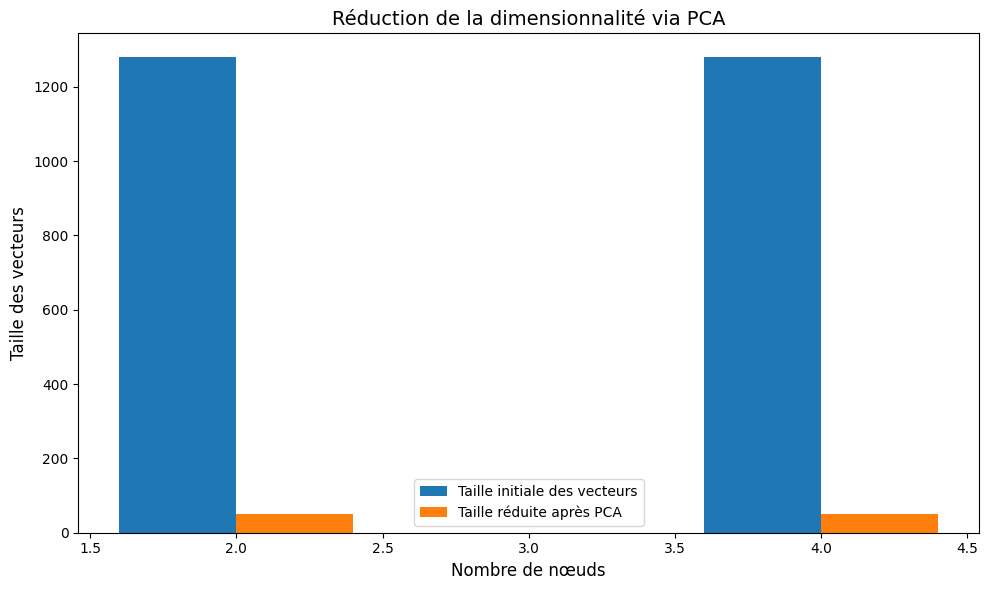

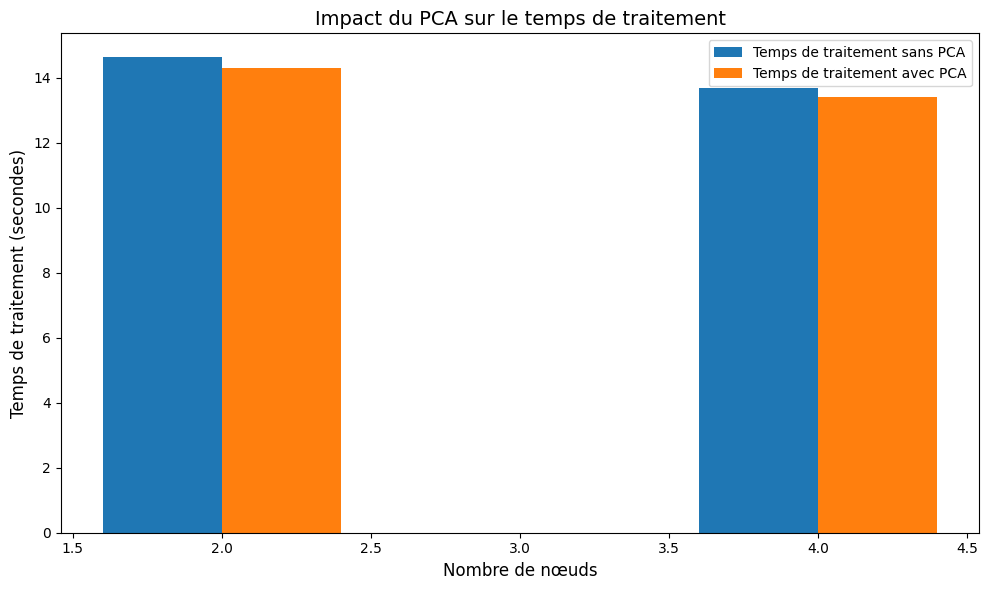

In [28]:
import matplotlib.pyplot as plt

# Fonction pour visualiser les résultats
def plot_dimension_reduction(dimension_reduction_df):
    """
    Trace un graphique montrant la réduction de la dimension et les gains de temps de traitement avec PCA.
    """
    # Taille de la figure pour le premier graphique
    fig, ax1 = plt.subplots(figsize=(10, 6))  # Plus grand format
    ax1.bar(
        dimension_reduction_df["nodes"] - 0.2,
        dimension_reduction_df["initial_vector_size"],
        width=0.4,
        label="Taille initiale des vecteurs"
    )
    ax1.bar(
        dimension_reduction_df["nodes"] + 0.2,
        dimension_reduction_df["reduced_vector_size"],
        width=0.4,
        label="Taille réduite après PCA"
    )
    ax1.set_xlabel("Nombre de nœuds", fontsize=12)
    ax1.set_ylabel("Taille des vecteurs", fontsize=12)
    ax1.set_title("Réduction de la dimensionnalité via PCA", fontsize=14)
    ax1.legend(fontsize=10)
    plt.tight_layout()  # Ajuster les marges pour une meilleure visibilité
    plt.show()

    # Taille de la figure pour le deuxième graphique
    fig, ax2 = plt.subplots(figsize=(10, 6))  # Taille augmentée
    ax2.bar(
        dimension_reduction_df["nodes"] - 0.2,
        dimension_reduction_df["processing_time_no_pca"],
        width=0.4,
        label="Temps de traitement sans PCA"
    )
    ax2.bar(
        dimension_reduction_df["nodes"] + 0.2,
        dimension_reduction_df["processing_time_with_pca"],
        width=0.4,
        label="Temps de traitement avec PCA"
    )
    ax2.set_xlabel("Nombre de nœuds", fontsize=12)
    ax2.set_ylabel("Temps de traitement (secondes)", fontsize=12)
    ax2.set_title("Impact du PCA sur le temps de traitement", fontsize=14)
    ax2.legend(fontsize=10)
    plt.tight_layout()  # Ajuster les marges pour une meilleure visibilité
    plt.show()

# Fonction pour générer un résumé des avantages du PCA
def summarize_pca_results(dimension_reduction_df):
    """
    Génère un texte résumant les avantages du PCA.
    """
    for _, row in dimension_reduction_df.iterrows():
        print(f"\n--- Résumé pour {row['nodes']} nœuds ---")
        print(f"- Taille initiale des vecteurs : {row['initial_vector_size']}")
        print(f"- Taille réduite des vecteurs : {row['reduced_vector_size']}")
        print(f"- Réduction de la dimension : {100 * (1 - row['reduced_vector_size'] / row['initial_vector_size']):.2f}%")
        print(f"- Temps de traitement sans PCA : {row['processing_time_no_pca']:.2f} secondes")
        print(f"- Temps de traitement avec PCA : {row['processing_time_with_pca']:.2f} secondes")
        print(f"- Gain en temps de traitement : {100 * (1 - row['processing_time_with_pca'] / row['processing_time_no_pca']):.2f}%")

# Visualisation les résultats
plot_dimension_reduction(dimension_reduction_df)


In [33]:
summarize_pca_results(dimension_reduction_df)


--- Résumé pour 2.0 nœuds ---
- Taille initiale des vecteurs : 1280.0
- Taille réduite des vecteurs : 50.0
- Réduction de la dimension : 96.09%
- Temps de traitement sans PCA : 30.24 secondes
- Temps de traitement avec PCA : 32.33 secondes
- Gain en temps de traitement : -6.93%

--- Résumé pour 4.0 nœuds ---
- Taille initiale des vecteurs : 1280.0
- Taille réduite des vecteurs : 50.0
- Réduction de la dimension : 96.09%
- Temps de traitement sans PCA : 31.89 secondes
- Temps de traitement avec PCA : 27.60 secondes
- Gain en temps de traitement : 13.44%


# execution du modèle avec PCA localement

<div class="blue-note">chargement d'images, extraction de caractéristiques avec MobileNetV2, réduction de dimensions via PCA, et sauvegarde sur S3 en Parquet/CSV</div>

In [34]:
image_path

'data/Test1'

<div class = "blue-note"> Effectue l'extraction des caractéristiques, applique le PCA et sauvegarde les résultats localement et sur S3</div>

<div class = "blue-note"> Vérifie la taille des vecteurs PCA dans les fichiers Parquet et CSV.
Peut être exécuté indépendamment pour des fichiers existants</div>

In [24]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, element_at, split, udf
from pyspark.sql.types import ArrayType, FloatType, StringType
from pyspark.ml.feature import PCA
from pyspark.ml.linalg import Vectors, VectorUDT
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import os
import tensorflow as tf
import logging

# ----------------------
# Configuration des logs
# ----------------------


# Réduction des logs TensorFlow
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)


# ----------------------
# Configuration Spark
# ----------------------
spark = SparkSession.builder \
    .appName("MobileNet-PCA") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.3.4") \
    .config("spark.hadoop.fs.s3a.aws.credentials.provider", "com.amazonaws.auth.DefaultAWSCredentialsProviderChain") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")  # Afficher uniquement les erreurs Spark

# Détection de l'environnement
ENVIRONMENT = "emr" if "AWS_EXECUTION_ENV" in os.environ else "local"
logger.info(f"Environnement détecté : {ENVIRONMENT}")

# ----------------------
# Chemins des résultats
# ----------------------
result_local_parquet = "data/Results/features_with_pca.parquet"
result_local_csv = "data/Results/features_with_pca.csv"
result_s3_parquet = "s3a://fruits-p8-oc/Results/features_with_pca.parquet"
result_s3_csv = "s3a://fruits-p8-oc/Results/features_with_pca.csv"

# ----------------------
# Modèle MobileNetV2 et diffusion des poids
# ----------------------
INPUT_SHAPE = (224, 224, 3)
base_model = MobileNetV2(weights="imagenet", include_top=True, input_shape=INPUT_SHAPE)
new_model = Model(inputs=base_model.input, outputs=base_model.layers[-2].output)
broadcast_weights = spark.sparkContext.broadcast(new_model.get_weights())

# Charger le modèle une seule fois
global_model = None
def model_fn():
    global global_model
    if global_model is None:
        base_model = MobileNetV2(weights="imagenet", include_top=True, input_shape=(224, 224, 3))
        global_model = Model(inputs=base_model.input, outputs=base_model.layers[-2].output)
    return global_model

# ----------------------
# Fonctions utilitaires
# ----------------------
def clean_path(path):
    if path.startswith("file://"):
        path = path[7:]
    return path.replace("%20", " ")

def preprocess_image(path):
    img = load_img(path, target_size=(224, 224))
    img_array = img_to_array(img)
    return preprocess_input(np.expand_dims(img_array, axis=0))


def extract_features(image_path):
    try:
        local_model = model_fn()
        img_array = preprocess_image(clean_path(image_path))
        features = local_model.predict(img_array, verbose=0).flatten()  # verbose=0 : silencieux
        return features.tolist()
    except Exception as e:
        print(f"Erreur avec {image_path}: {e}")
        return []


# ----------------------
# UDF pour Spark
# ----------------------
extract_features_udf = udf(lambda path: extract_features(path), ArrayType(FloatType()))
to_vector_udf = udf(lambda features: Vectors.dense(features) if features else None, VectorUDT())
vector_to_string_udf = udf(lambda vector: ",".join(map(str, vector.toArray())), StringType())

# ----------------------
# Chargement des images
# ----------------------
image_path = "data/Test1" if ENVIRONMENT == "local" else "s3a://fruits-p8-oc/data/Test1"
images = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
    .load(image_path)
    .withColumn("image_path", col("image.origin"))
    .withColumn("label", element_at(split(col("image_path"), "/"), -2))
)

# ----------------------
# Extraction des caractéristiques
# ----------------------
features_df = images.withColumn("features", extract_features_udf(col("image_path")))
features_df = features_df.filter(col("features").isNotNull()).withColumn("features_vector", to_vector_udf(col("features")))

# ----------------------
# Application de PCA
# ----------------------
if features_df.count() > 0:
    pca = PCA(k=50, inputCol="features_vector", outputCol="pcaFeatures")
    pca_model = pca.fit(features_df)
    features_with_pca = pca_model.transform(features_df)
    features_with_pca = features_with_pca.withColumn("feature_vector_str", vector_to_string_udf(col("pcaFeatures")))

    # Sauvegarde des résultats en local et sur S3
    for path_parquet, path_csv in [(result_local_parquet, result_local_csv), 
                                   (result_s3_parquet, result_s3_csv)]:
        features_with_pca.coalesce(1).select("image_path", "label", "pcaFeatures") \
            .write.mode("overwrite").parquet(path_parquet)
        features_with_pca.coalesce(1).select("image_path", "label", "feature_vector_str") \
            .write.mode("overwrite").csv(path_csv, header=True)

    logger.info("Résultats sauvegardés localement et sur S3.")
else:
    logger.warning("Aucun vecteur de caractéristiques valide trouvé.")


In [25]:
from pyspark.sql.functions import size, col, split, expr
from pyspark.ml.functions import vector_to_array  # Fonction pour transformer en Array

def check_result_dimensions(parquet_path, csv_path):
    """
    Vérifier les dimensions des résultats Parquet et CSV,
    et afficher la taille des vecteurs PCA.
    """
    print(f"\n--- Vérification des résultats pour {parquet_path} et {csv_path} ---")
    
    # Lire le fichier Parquet
    parquet_df = spark.read.parquet(parquet_path)
    print("Exemple des caractéristiques PCA (Parquet) :")
    parquet_df.select("pcaFeatures").show(5, truncate=False)
    
    # Convertir SparseVector en DenseVector puis en tableau
    parquet_df_with_size = parquet_df.withColumn("pca_values", vector_to_array(col("pcaFeatures"))) \
                                     .withColumn("pca_size", size(col("pca_values")))
    
    print("Taille des vecteurs PCA (Parquet) :")
    parquet_df_with_size.select("pca_size").distinct().show()
    
    # Lire et afficher des exemples de CSV
    csv_df = spark.read.option("header", "true").csv(csv_path)
    print("Exemple des caractéristiques PCA (CSV) :")
    csv_df.select("feature_vector_str").show(5, truncate=False)

    # Calculer la taille des vecteurs PCA depuis le CSV
    print("Taille des vecteurs PCA (CSV) :")
    csv_df.withColumn("vector_length", size(split(col("feature_vector_str"), ','))) \
          .select("vector_length").distinct().show()


In [26]:
# Appel pour vérifier les dimensions
check_result_dimensions("data/Results/features_with_pca.parquet", "data/Results/features_with_pca.csv")
check_result_dimensions("s3a://fruits-p8-oc/Results/features_with_pca.parquet", "s3a://fruits-p8-oc/Results/features_with_pca.csv")



--- Vérification des résultats pour data/Results/features_with_pca.parquet et data/Results/features_with_pca.csv ---
Exemple des caractéristiques PCA (Parquet) :
+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------